**Table of contents**<a id='toc0_'></a>    
- 1. [导入模块](#toc1_)    
- 2. [预处理](#toc2_)    
- 3. [两组比较](#toc3_)    
- 4. [方差分析 （多组比较分析）](#toc4_)    
  - 4.1. [单因素方差分析](#toc4_1_)    
  - 4.2. [双因素方差分析](#toc4_2_)    
    - 4.2.1. [无交互作用的方差分析](#toc4_2_1_)    
    - 4.2.2. [有交互作用的方差分析](#toc4_2_2_)    
- 5. [相关分析](#toc5_)    
- 6. [回归分析](#toc6_)    
  - 6.1. [模拟数据](#toc6_1_)    
  - 6.2. [线性回归分析](#toc6_2_)    
    - 6.2.1. [LM](#toc6_2_1_)    
      - 6.2.1.1. [探索分析](#toc6_2_1_1_)    
      - 6.2.1.2. [相关性分析](#toc6_2_1_2_)    
      - 6.2.1.3. [最小二乘法回归分析](#toc6_2_1_3_)    
      - 6.2.1.4. [多重共线性现象](#toc6_2_1_4_)    
        - 6.2.1.4.1. [方差膨胀因子（VIF）](#toc6_2_1_4_1_)    
        - 6.2.1.4.2. [Ridge 回归](#toc6_2_1_4_2_)    
        - 6.2.1.4.3. [Lasso 回归](#toc6_2_1_4_3_)    
        - 6.2.1.4.4. [Ridge vs Lasso 回归](#toc6_2_1_4_4_)    
        - 6.2.1.4.5. [ElasticNet [推荐] ](#toc6_2_1_4_5_)    
    - 6.2.2. [LMM](#toc6_2_2_)    
    - 6.2.3. [GLM](#toc6_2_3_)    
    - 6.2.4. [GLMM](#toc6_2_4_)    
    - 6.2.5. [线性回归模型检验](#toc6_2_5_)    
      - 6.2.5.1. [误差正态性](#toc6_2_5_1_)    
  - 6.3. [非线性回归分析](#toc6_3_)    
    - 6.3.1. [多项式拟合](#toc6_3_1_)    
    - 6.3.2. [curve fit method](#toc6_3_2_)    
    - 6.3.3. [learning method](#toc6_3_3_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# 1. <a id='toc1_'></a>[导入模块](#toc0_)

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context='paper', style='whitegrid', palette='husl')

import statsmodels.api as sm
import statsmodels.formula.api as smf

import pingouin as pg

# 2. <a id='toc2_'></a>[预处理](#toc0_)

# 3. <a id='toc3_'></a>[两组比较](#toc0_)

In [ ]:
# pg.ttest?
pg

Help on package pingouin:

NAME
    pingouin - # Import pingouin objects

PACKAGE CONTENTS
    bayesian
    circular
    config
    contingency
    correlation
    datasets (package)
    distribution
    effsize
    equivalence
    multicomp
    multivariate
    nonparametric
    pairwise
    parametric
    plotting
    power
    regression
    reliability
    utils

DATA
    options = {'round': None, 'round.column.BF10': <function _format_bf>, ...

VERSION
    0.5.5

FILE
    d:\programfiles\miniconda3\envs\skbio\lib\site-packages\pingouin\__init__.py




# 4. <a id='toc4_'></a>[方差分析 （多组比较分析）](#toc0_)

## 4.1. <a id='toc4_1_'></a>[单因素方差分析](#toc0_)

In [161]:
# pg.anova?



## 4.2. <a id='toc4_2_'></a>[双因素方差分析](#toc0_)

### 4.2.1. <a id='toc4_2_1_'></a>[无交互作用的方差分析](#toc0_)

### 4.2.2. <a id='toc4_2_2_'></a>[有交互作用的方差分析](#toc0_)

# 5. <a id='toc5_'></a>[相关分析](#toc0_)

通过计算各自变量与因变量之间的 皮尔森相关系数，可以初步判断是否存在线性关系:
- 相关系数接近1或-1表明可能存在强线性关系;
- 而接近0则表明关系较弱。

In [22]:
import pingouin as pg
import numpy as np

x = np.random.rand(100)
y = 2.5 * x + np.random.normal(0, 0.1, 100)

pg.corr(x, y, method='pearson')

,n,r,CI95%,p-val,BF10,power
pearson,100,0.991576,"[0.99, 0.99]",8.319964e-89,2.138e+84,1.0


# 6. <a id='toc6_'></a>[回归分析](#toc0_)

| **回归方法**                         | **使用条件**                                      | **建模评价指标**                        | **算法/方法**                | **Python实现**                                               |
| -------------------------------- | --------------------------------------------- | --------------------------------- | ------------------------ | ---------------------------------------------------------- |
| **线性回归 (Linear Regression)**     | 自变量与因变量之间存在线性关系，无多重共线性，数据独立同分布。               | R²、调整后的 R²、AIC/BIC、均方误差（MSE）、残差分析 | 最小二乘法（OLS）               | `sklearn.linear_model.LinearRegression`  `statsmodels.OLS` |
| **广义线性回归 (GLM)**                 | `因变量`服从非正态分布（如二分类、计数数据），需要使用链接函数。               | AIC/BIC、似然比检验（LR检验）、偏差残差分析        | Logistic 回归、泊松回归等        | `statsmodels.formula.api.glm`                              |
| **混合线性回归 (LMM)**                 | 数据有层级结构（如重复测量或分组数据），需要考虑随机效应和固定效应。            | AIC/BIC、随机效应的方差估计、似然比检验           | 随机截距或随机斜率模型              | `statsmodels.formula.api.mixedlm`                          |
| **广义混合线性回归 (GLMM)**              | `因变量`服从非正态分布（如二分类、计数数据），且数据有层级结构，需要考虑随机效应和固定效应。 | AIC/BIC、似然比检验、偏差残差分析、模型解释度        | Logistic 混合效应回归、泊松混合效应回归 | `statsmodels.formula.api.mixedlm` (与GLM结合)                 |
| **非线性回归 (Nonlinear Regression)** | 因变量与自变量之间存在线性关系无法拟合的非线性关系。                    | R²、AIC/BIC、均方误差（MSE）、残差分析         | 非线性最小二乘法（Curve fitting）  | `scipy.optimize.curve_fit`                                 |

分类如下：
- 线性回归
  - 线性回归
    - 普通线性回归 (LM)
    - 混合线性回归 (LMM)
  - 广义线性回归  
    - 普通线性回归 (GLM)
    - 混合线性回归 (GLMM)
- 非线性回归

---

|模型类型	|适用场景	|模型特点|
|---|---|---|
|线性模型 (LM)	|连续响应变量，变量之间的线性关系	|响应变量与自变量线性关系，假设独立同分布|
|线性混合模型 (LMM)	|连续响应变量，有随机效应的情况（如重复测量）	|包含固定效应和随机效应，控制群体结构|
|广义线性模型 (GLM)	|非连续响应变量（如计数、二分类等）	|处理不同分布的因变量（如Poisson、Binomial）|
|广义线性混合模型 (GLMM)	|非连续响应变量，包含随机效应的情况	|结合GLM和LMM，适用于计数型/二分类数据并控制随机效应|

|**线性和非线性**| **回归类型**             | **描述**                          | **例子**                              |
| -------------------- | -------------------- | ------------------------------- | ----------------------------------- |
|线性| **线性回归 （LM）**             | 因变量和自变量之间的关系是线性的。               | **OLS**，**PLS**，**Lasso**，**Ridge** |
|| **广义线性回归（GLM）**      | 允许`因变量`服从不同的分布，通过链接函数进行建模。        | **逻辑回归**，**泊松回归**，**Gamma回归**       |
|| **线性混合效应模型（LMM）**    | 具有`固定效应和随机效应`，适用于层次结构数据。          | **混合效应模型**（如：学生数据中的班级效应）            |
|| **广义线性混合效应模型（GLMM）** | 结合 GLM 和 LMM，适用于有随机效应的广义线性回归模型。 | **GLMM**（如：具有层次结构的计数数据分析）           |
|非线性| **非线性回归**            | 因变量与自变量之间的关系是非线性的，常通过数值方法进行拟合。  | **指数回归**，**对数回归**，**幂律回归**   **随机森林**       |


总结
- 线性回归（Linear Regression） 是回归分析中的基础模型，能够有效地描述因变量与自变量之间的线性关系。
- OLS、PLS、Lasso、Ridge、ElastiNet 都属于 线性回归 的不同变种或方法，适用于不同的应用场景。
- 广义线性模型（GLM） 扩展了线性回归，允许因变量服从各种分布，适用于更多类型的回归问题。
- 混合效应模型（LMM 和 GLMM） 进一步扩展了线性回归，通过引入随机效应来处理复杂的数据结构，适用于层次化数据。
- 非线性回归 处理因变量和自变量之间的非线性关系，常常用于无法用简单线性公式描述的现象。
- 每种方法都有其特定的适用场景，选择哪种方法主要取决于你的数据特点、假设以及具体问题。

## 6.1. <a id='toc6_1_'></a>[模拟数据](#toc0_)

In [149]:
data = pd.DataFrame(
    {
    'y1': 2.5 * np.random.rand(100) + np.random.normal(0, 0.1, 100),
    'y2': np.random.choice([0, 1], size=100),
    'y3': np.random.choice(['A', 'B', 'C'], size=100),
    'x1': np.random.rand(100), 
    'x2': np.random.rand(100) * 3 + 1,
    'x3': np.random.rand(100) * 5 - 2,
    'batch': np.random.choice(['A', 'B'], size=100),
    'site': np.random.choice(['X', 'Y', 'Z'], size=100)
    }
)

data.head(3)

,y1,y2,y3,x1,x2,x3,batch,site
0,0.377828,1,A,0.073409,1.632171,0.720821,B,Z
1,0.459164,1,B,0.233360,2.108058,0.835509,A,X
2,0.576038,1,C,0.052322,1.612235,2.407122,A,Y


## 6.2. <a id='toc6_2_'></a>[线性回归分析](#toc0_)

### 6.2.1. <a id='toc6_2_1_'></a>[LM](#toc0_)

- 最小二乘法（OLS）
    - 适用于因变量和自变量之间存在线性关系的情况。
    - 通过最小化预测值与实际值之间的平方误差来估计模型参数。
    - 适用于连续型因变量。
- 偏最小二乘法（PLS）
    - 适用于自变量之间存在多重共线性的情况。
    - 通过提取潜在变量来减少自变量的维度，同时保留对因变量的解释能力。
    - 适用于连续型因变量。

#### 6.2.1.1. <a id='toc6_2_1_1_'></a>[探索分析](#toc0_)

In [192]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler


data_encoded = data.copy()
data_encoded = pd.get_dummies(columns=['y3', 'batch', 'site'], data=data_encoded, drop_first=True)

# 对分类变量进行标签编码
# onehot = OneHotEncoder(
#     drop='first'
# )
# onehot_features = onehot.fit_transform(data_encoded[['y3', 'batch', 'site']])
# onehot_features_df = pd.DataFrame(onehot_features.toarray(), columns=onehot.get_feature_names_out(['y3', 'batch', 'site']))
# onehot_features_df

# data_encoded['y3'] = LabelEncoder().fit_transform(data_encoded['y3'])
# data_encoded['batch'] = LabelEncoder().fit_transform(data_encoded['batch'])
# data_encoded['site'] = LabelEncoder().fit_transform(data_encoded['site'])

# 对数值变量进行标准化
scaler = StandardScaler()
data_encoded[['y1', 'x1', 'x2', 'x3']] = scaler.fit_transform(data_encoded[['y1', 'x1', 'x2', 'x3']])

data_encoded.head()

,y1,y2,x1,x2,x3,y3_B,y3_C,batch_B,site_Y,site_Z
0,-1.004482,1,-1.511427,-1.152865,0.073584,False,False,True,False,True
1,-0.890830,1,-0.955703,-0.565104,0.156512,True,False,False,False,False
2,-0.727519,1,-1.584693,-1.177488,1.292888,False,True,False,True,False
3,-0.460333,0,-1.381108,0.121625,0.791618,True,False,True,True,False
4,0.756046,0,-0.583674,-0.515964,-1.697308,True,False,True,True,False


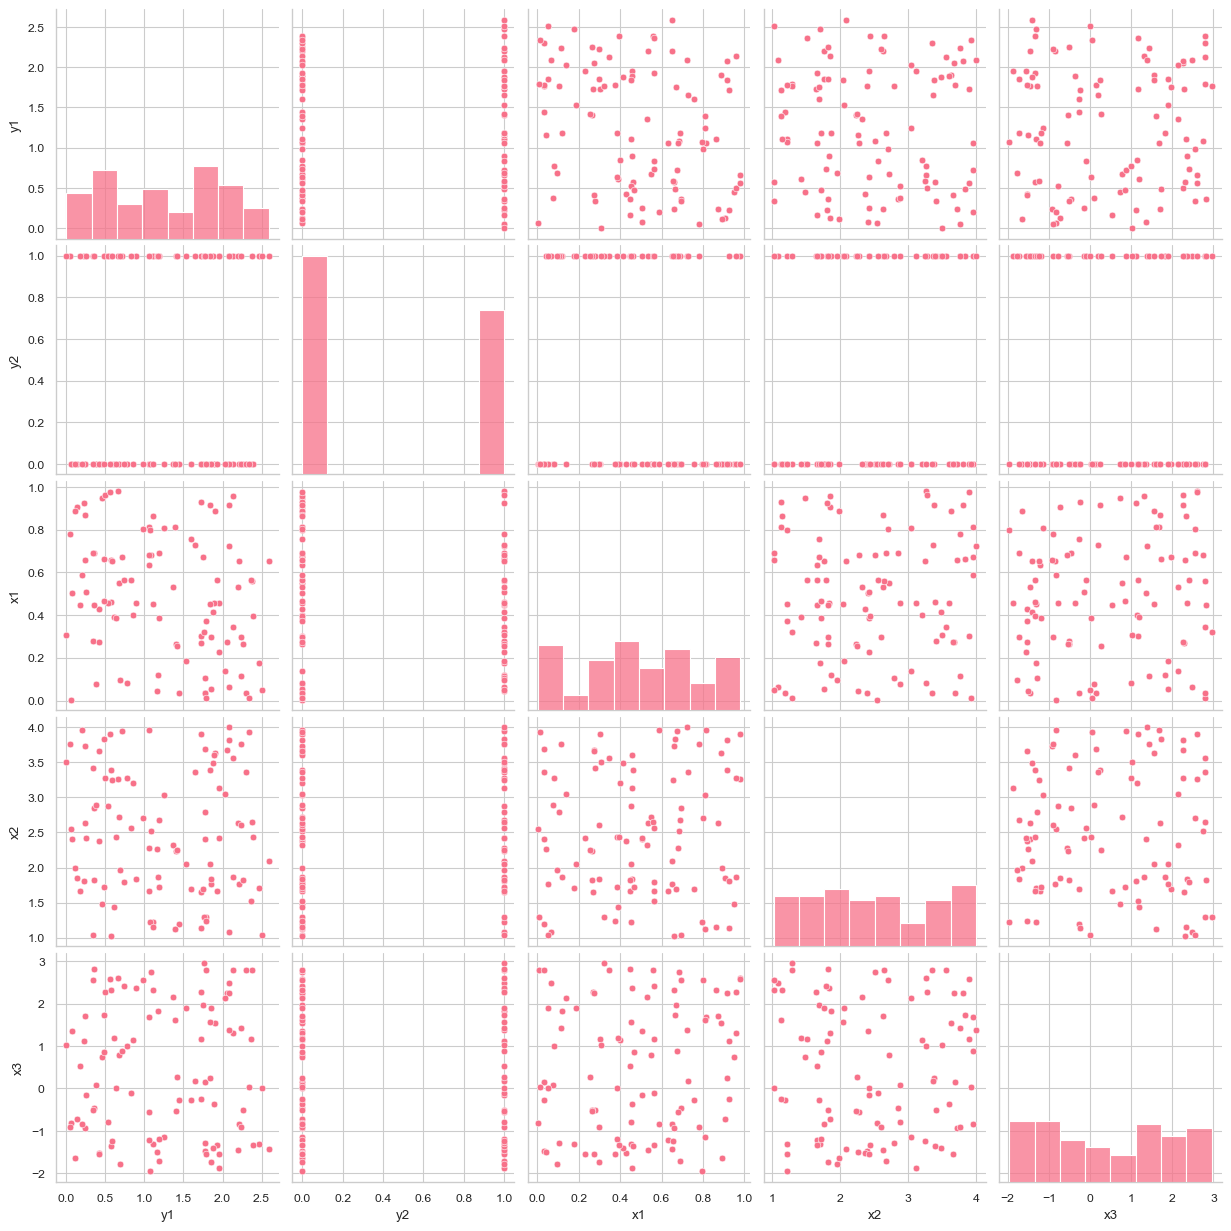

In [135]:
# 可视化散点图
sns.pairplot(data)

#### 6.2.1.2. <a id='toc6_2_1_2_'></a>[相关性分析](#toc0_)

In [58]:
# 计算皮尔逊相关系数
corr_results = pg.corr(data['x1'], data['y1'], method='pearson')
print(corr_results)


           n         r          CI95%     p-val   BF10     power
pearson  100  0.065315  [-0.13, 0.26]  0.518522  0.154  0.098986


#### 6.2.1.3. <a id='toc6_2_1_3_'></a>[最小二乘法回归分析](#toc0_)

In [74]:
lm_ols = smf.ols('y1 ~ x1 + x2 + x3', data=data).fit()

lm_results = lm_ols.summary()
print(lm_results)

                            OLS Regression Results                            
Dep. Variable:                     y1   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                 -0.012
Method:                 Least Squares   F-statistic:                    0.5934
Date:                Tue, 16 Dec 2025   Prob (F-statistic):              0.621
Time:                        10:33:35   Log-Likelihood:                -103.47
No. Observations:                 100   AIC:                             214.9
Df Residuals:                      96   BIC:                             225.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2635      0.239      5.297      0.0

结果：
- R-squared: 是回归模型拟合优度的指标，值越接近 1，表示模型对数据的拟合效果越好。
- F-statistic：用于检验模型是否显著。
- p-value：对于每个自变量的 t 检验，p 值越小（通常小于 0.05），说明自变量与因变量之间的关系越显著。

#### 6.2.1.4. <a id='toc6_2_1_4_'></a>[多重共线性现象](#toc0_)

什么是多重共线性？
- 多重共线性是指在多元线性回归分析中，自变量之间存在高度相关性的现象。这种相关性会导致回归系数的不稳定性和解释困难。


##### 6.2.1.4.1. <a id='toc6_2_1_4_1_'></a>[方差膨胀因子（VIF）](#toc0_)

当多个自变量之间存在多重共线性时，线性回归模型的回归系数可能会不稳定。方差膨胀因子（VIF） 是用来诊断多重共线性的一种方法：
- VIF 越大，表示该自变量与其他自变量之间的相关性越高，可能存在共线性问题；
- 一般来说，VIF 值大于 10 可能表示存在严重的多重共线性。

In [66]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


# 计算每个自变量的 VIF
X = add_constant(data[['x1', 'x2', 'x3']])
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)


  Variable        VIF
0    const  11.780507
1       x1   1.002237
2       x2   1.028289
3       x3   1.029152


解释：
- 如果 VIF 大于 10，可能表示该自变量与其他自变量之间有较高的多重共线性，需要考虑`剔除某些自变量`或使用`其他方法（如岭回归、Lasso 回归等`）。

##### 6.2.1.4.2. <a id='toc6_2_1_4_2_'></a>[Ridge 回归](#toc0_)

岭回归通过对回归系数施加 L2 正则化 来控制模型的复杂度。具体来说，它在最小化残差平方和（即普通最小二乘法 OLS 的目标）时，加入了一个正则化项，该项与回归系数的平方和成正比。通过这种方式，岭回归惩罚大系数，从而减少模型对训练数据的过拟合。

In [103]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0) # alpha 即为正则化强度λ
ridge_model.fit(data[['x1', 'x2', 'x3']], data['y1'])

print("Ridge Coefficients:", ridge_model.coef_)
print("Ridge Intercept:", ridge_model.intercept_)

Ridge Coefficients: [ 0.05793854 -0.00146247  0.04039404]
Ridge Intercept: 1.1910307864456795


##### 6.2.1.4.3. <a id='toc6_2_1_4_3_'></a>[Lasso 回归](#toc0_)

Lasso 回归则通过对回归系数施加 L1 正则化 来控制模型复杂度。与岭回归不同，Lasso 回归不仅会减小回归系数的绝对值，还会 将某些回归系数缩减为零，从而实现特征选择的效果。

特点：
- Lasso 回归会强制一些回归系数为零，这有助于 特征选择，即自动选择对预测有贡献的自变量。
- 适用于当自变量较多时，且你希望从中选择出最重要的特征（例如：高维稀疏数据，特征选择问题）。
- Lasso 回归对于一些无关变量（冗余的特征）会将其系数缩小到零，从而实现特征选择。

In [105]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.1)  # alpha 即为正则化强度λ
lasso_model.fit(data[['x1', 'x2', 'x3']], data['y1'])
print("Lasso Coefficients:", lasso_model.coef_)
print("Lasso Intercept:", lasso_model.intercept_)

Lasso Coefficients: [0. 0. 0.]
Lasso Intercept: 1.2425740367920475


##### 6.2.1.4.4. <a id='toc6_2_1_4_4_'></a>[Ridge vs Lasso 回归](#toc0_)

| 特性         | **岭回归（Ridge Regression）** | **Lasso 回归（Lasso Regression）** |
| ---------- | ------------------------- | ------------------------------ |
| **正则化类型**  | L2 正则化（系数的平方和惩罚）          | L1 正则化（系数的绝对值和惩罚）              |
| **回归系数收缩** | 将回归系数收缩到较小值，但不为零          | 会将一些回归系数收缩为零，`实现特征选择`            |
| **特征选择**   | 不进行特征选择，只是减小系数            | 自动进行特征选择，选择重要特征                |
| **适用场景**   | 适用于多重共线性问题，模型比较复杂时        | 适用于高维数据或需要特征选择的场景              |
| **计算复杂度**  | 相对较低，因为仅涉及 L2 正则化         | 计算复杂度较高，因为涉及 L1 正则化            |
| **系数的稀疏性** | 不产生稀疏系数（系数不会为零）           | 会产生稀疏系数（一些系数为零）                |


选择时的考虑：
- 岭回归 更适用于 共线性问题 或 高维数据，尤其是在所有特征都重要时，可以通过减小回归系数来避免过拟合。
- Lasso 回归 适用于 特征选择 的情况，当你希望从大量特征中选择出对模型预测最有贡献的变量时，Lasso 是一个很好的选择。

##### 6.2.1.4.5. <a id='toc6_2_1_4_5_'></a>[ElasticNet [推荐]](#toc0_)  [&#8593;](#toc0_)

如果你既希望在模型中进行特征选择，又希望控制多重共线性问题，ElasticNet 回归可能是一个很好的选择。ElasticNet 是 岭回归 和 Lasso 回归 的结合，既使用 L1 正则化（Lasso）又使用 L2 正则化（Ridge），适合于高维数据，尤其是当特征数量多于样本数时。

In [107]:
from sklearn.linear_model import ElasticNet

elastic_net_model = ElasticNet(alpha=0.1, l1_ratio=0.5)  # l1_ratio 控制 L1 和 L2 正则化的比例
elastic_net_model.fit(data[['x1', 'x2', 'x3']], data['y1'])
print("ElasticNet Coefficients:", elastic_net_model.coef_)
print("ElasticNet Intercept:", elastic_net_model.intercept_)

ElasticNet Coefficients: [ 0.         -0.          0.01906318]
ElasticNet Intercept: 1.228302721822295


### 6.2.2. <a id='toc6_2_2_'></a>[LMM](#toc0_)

In [132]:
# lmm_model = smf.mixedlm("y1 ~ x1 + x2 + x3", data, groups=data["batch"])
# lmm_model = smf.mixedlm("y1 ~ x1 + x2 + x3", data, groups=data["site"])

data['batch_site'] = data['batch'] + "_" + data['site']
lmm_model = smf.mixedlm("y1 ~ x1 + x2 + x3", data, groups=data["batch_site"]) # 有多个随机效应时，可以将它们组合成一个新的分组变量

lmm_results = lmm_model.fit()
print(lmm_results.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: y1       
No. Observations: 100     Method:             REML     
No. Groups:       6       Scale:              0.4744   
Min. group size:  13      Log-Likelihood:     -108.5651
Max. group size:  21      Converged:          Yes      
Mean group size:  16.7                                 
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     1.203    0.243  4.944 0.000  0.726  1.679
x1            0.139    0.248  0.559 0.576 -0.347  0.624
x2            0.047    0.078  0.594 0.552 -0.107  0.200
x3           -0.127    0.050 -2.531 0.011 -0.225 -0.029
Group Var     0.000    0.030                           



d:\ProgramFiles\miniconda3\envs\skbio\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
d:\ProgramFiles\miniconda3\envs\skbio\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


          W      pval  normal
0  0.959948  0.003987   False


<Axes: xlabel='Theoretical quantiles', ylabel='Ordered quantiles'>

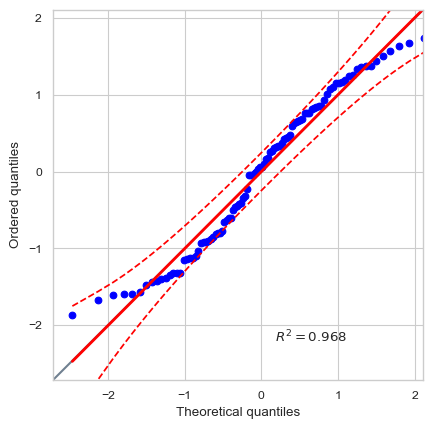

In [119]:
print(pg.normality(lmm_results.resid))
pg.qqplot(lmm_results.resid)

### 6.2.3. <a id='toc6_2_3_'></a>[GLM](#toc0_)

In [111]:
glm_model = smf.glm("y2 ~ x1 + x2 + x3", data, family=sm.families.Gaussian())
glm_results = glm_model.fit()
print(glm_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     y2   No. Observations:                  100
Model:                            GLM   Df Residuals:                       96
Model Family:                Gaussian   Df Model:                            3
Link Function:               Identity   Scale:                         0.24387
Method:                          IRLS   Log-Likelihood:                -69.297
Date:                Tue, 16 Dec 2025   Deviance:                       23.412
Time:                        11:01:20   Pearson chi2:                     23.4
No. Iterations:                     3   Pseudo R-squ. (CS):            0.03221
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5725      0.164      3.488      0.0

### 6.2.4. <a id='toc6_2_4_'></a>[GLMM](#toc0_)

In [ ]:
glmm_model = smf.mixedlm("y2 ~ x1 + x2 + x3", data, groups=data["y2"], family=sm.families.Binomial())
glmm_results = glmm_model.fit()
print(glmm_results.summary())

### 6.2.5. <a id='toc6_2_5_'></a>[线性回归模型检验](#toc0_)

#### 6.2.5.1. <a id='toc6_2_5_1_'></a>[误差正态性](#toc0_)

线性回归模型假设误差项服从正态分布。如果残差不符合正态分布，可能需要考虑非线性模型或对数据进行变换。常用的正态性检验方法包括 Shapiro-Wilk 检验 和 Q-Q图。

,W,pval,normal
0,0.971802,0.030416,False


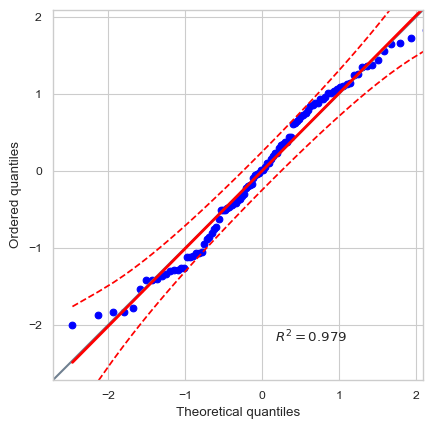

In [100]:
predicted = lm_ols.fittedvalues
residuals = lm_ols.resid

# sm.qqplot(residuals, line ='s')
pg.qqplot(residuals)
pg.normality(residuals, method='shapiro', alpha=0.05)

## 6.3. <a id='toc6_3_'></a>[非线性回归分析](#toc0_)

### 6.3.1. <a id='toc6_3_1_'></a>[多项式拟合](#toc0_)

对每个 x 构建 a0x + a1x2 + a3x3 + ... 特征，从而模拟非线性关系：

Text(0.0, 1.0, 'Figure. Polynomial Regression with Confidence Interval')

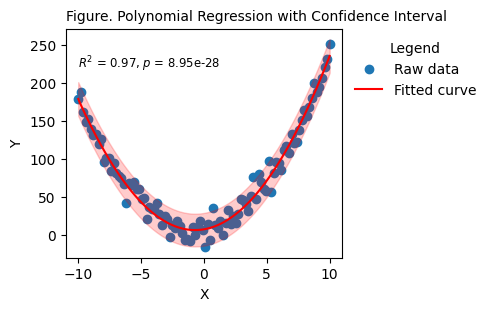

In [1]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures


# 生成示例数据：y = 2x^2 + 3x + 5 + 噪声
x = np.linspace(-10, 10, 100)
y = 2 * x**2 + 3 * x + 5 + np.random.normal(0, 10, size=x.shape)

# 使用 sklearn 生成二次多项式特征
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(x.reshape(-1, 1))  # 转换为二维数组

# 添加截距项
X_poly = sm.add_constant(X_poly)

# 使用 statsmodels 进行 OLS 拟合
model = sm.OLS(y, X_poly).fit()

# 输出回归结果
# print(model.summary())

# 绘制拟合结果
y_pred = model.predict(X_poly)

# 获得预测值和置信区间
prediction = model.get_prediction(X_poly)
pred_summary = prediction.summary_frame(alpha=0.05)  # 95%置信区间
y_pred = pred_summary['mean']
lower_ci = pred_summary['obs_ci_lower']
upper_ci = pred_summary['obs_ci_upper']

fig, ax = plt.subplots(layout='constrained', figsize=(3*1.6, 3))

ax.scatter(x, y, label="Raw data")

ax.plot(x, y_pred, color='red', label="Fitted curve")
ax.fill_between(x, lower_ci, upper_ci, color='red', alpha=0.2)
ax.text(-10, 220, f"$R^2$ = {model.rsquared:.2f}, $p$ = {model.pvalues[1]:.2e}", fontsize='small', color='black', transform=ax.transData)

ax.legend(title='Legend', loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Figure. Polynomial Regression with Confidence Interval", loc='left', fontsize='medium')

### 6.3.2. <a id='toc6_3_2_'></a>[curve fit method](#toc0_)

In [7]:
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

def model(x, a, b, c):
    return a * np.exp(-b * x) + c

x = np.linspace(0, 4, 50)
y = model(x, 2.5, 1.3, 0.5) + 0.2 * np.random.normal(size=x.size)

popt, pcov = curve_fit(model, x, y, p0=(1, 1e-6, 1))
print("Fitted parameters:", popt)
print("Covariance of parameters:", pcov)

# Calculate and print model performance metrics
y_pred = model(x, *popt)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

Fitted parameters: [2.52782822 1.22519256 0.45200672]
Covariance of parameters: [[ 0.01803118  0.00651603 -0.00119054]
 [ 0.00651603  0.02139489  0.00708815]
 [-0.00119054  0.00708815  0.00411848]]
Mean Squared Error: 0.05034123084723911
R^2 Score: 0.8944311093090139


### 6.3.3. <a id='toc6_3_3_'></a>[learning method](#toc0_)

In [23]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)